In [ ]:
#analysis from customer dtaset

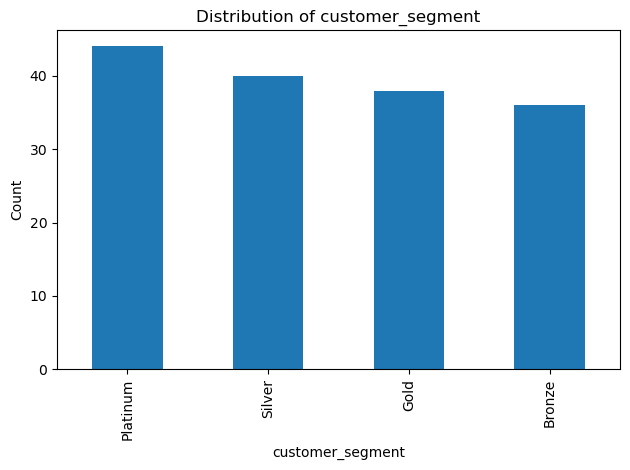

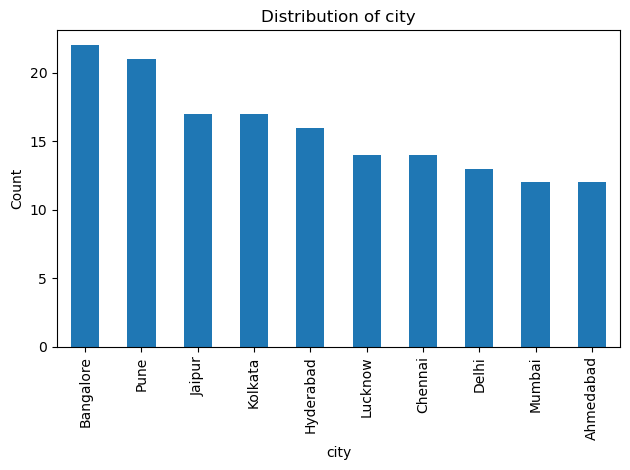

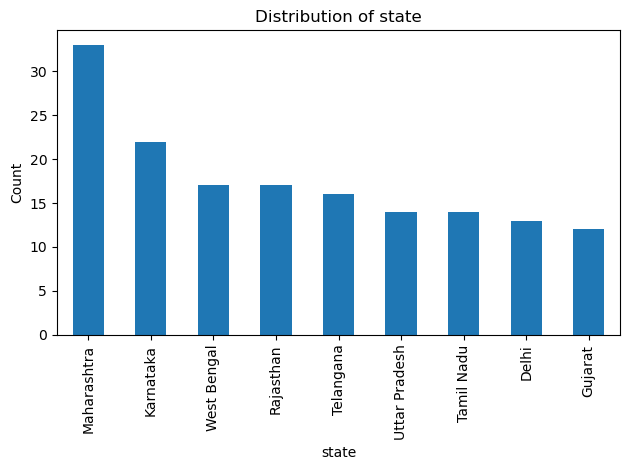

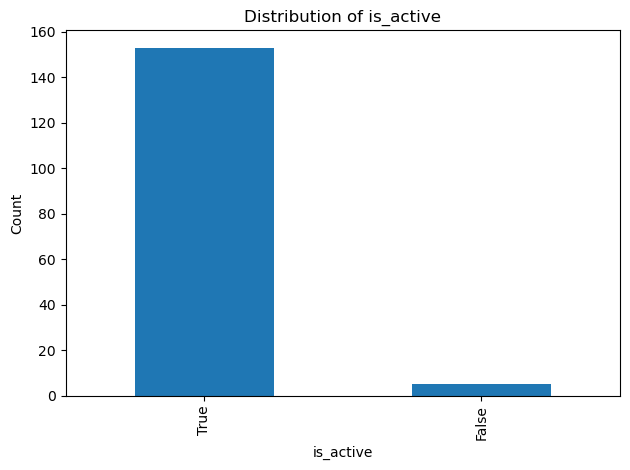

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
df1 = pd.read_csv("silver\customers.csv")

for col in ["customer_segment", "city", "state", "is_active"]:
    df1[col].value_counts().plot(kind="bar", title=f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

In [ ]:
# statistical analysis on categorical columns

# h0 = "There is no association between customer_segment and city/state/is_active"
# h1 = "There is an association between customer_segment and city/state/is_active"

In [6]:
# ---------- Chi-square test (is the relationship significant?) ----------
from scipy.stats import chi2_contingency

alpha = 0.05

for col in ["city", "state", "is_active"]:
    table = pd.crosstab(df1[col], df1["customer_segment"])
    chi2, p, dof, _ = chi2_contingency(table)
    print(f"customer_segment vs {col}: chi2={chi2:.2f}, p-value={p:.4f}")

    if p < alpha:
        print("Reject the null hypothesis. customer_segment and", col, "are related.\n")
    else:
        print("Fail to reject the null hypothesis. No significant relationship with", col, "\n")

customer_segment vs city: chi2=29.77, p-value=0.3246
Fail to reject the null hypothesis. No significant relationship with city 

customer_segment vs state: chi2=28.78, p-value=0.2286
Fail to reject the null hypothesis. No significant relationship with state 

customer_segment vs is_active: chi2=2.28, p-value=0.5170
Fail to reject the null hypothesis. No significant relationship with is_active 



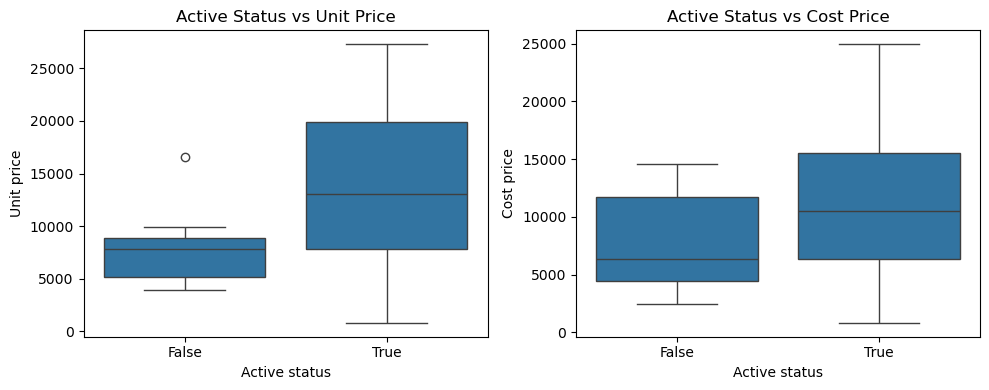

In [9]:
# Install once if needed:
# %pip install pandas matplotlib seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Read the cleaned product data
products = pd.read_csv("silver/products.csv")

# Create side-by-side box plots
fig, axarr = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(data=products, x="is_active", y="unit_price", ax=axarr[0])
axarr[0].set_title("Active Status vs Unit Price")
axarr[0].set_xlabel("Active status")
axarr[0].set_ylabel("Unit price")

sns.boxplot(data=products, x="is_active", y="cost_price", ax=axarr[1])
axarr[1].set_title("Active Status vs Cost Price")
axarr[1].set_xlabel("Active status")
axarr[1].set_ylabel("Cost price")

plt.tight_layout()
plt.show()

est Assumptions
Before applying statistical tests to any dataset, we need to verify the assumptions of each test to ensure that the results are statistically valid.

1. Independent Observations
Each row represents an individual customer.
Customers' observations should be independent of one another.
2. Normality
For a t-test or ANOVA, the data within each group should be approximately normally distributed.
This assumption can be checked using a histogram, Q-Q plot, or Shapiro-Wilk test. # ie since p value is much higher than significance value(0.005) then it is normal distribution.
3. Homogeneity of Variance
For a standard independent t-test or one-way ANOVA, group variances should be approximately equal.
This can be checked using Levene's test.# ie If the p-value from Levene's test is greater than your chosen significance level (α = 0.05), you can assume equal variances.
4. Categorical Variables
For the Chi-square test, variables must be categorical.
Expected frequencies should generally be at least 5 in each cell for the usual approximation to be reliable.
5. Significance Level
The significance level is set to 0.05 (5%).
If the p-value is less than 0.05, we reject the null hypothesis.
If the p-value is greater than or equal to 0.05, we fail to reject the null hypothesis.
Conclusion
These assumptions will be checked before interpreting the results of the statistical tests used to identify factors associated with customer churn.

In [10]:
# Install once if needed:
# %pip install pandas scipy

import pandas as pd
from scipy import stats

products = pd.read_csv("silver/products.csv")
products["unit_price"] = pd.to_numeric(products["unit_price"], errors="coerce")

active_prices = products.loc[products["is_active"] == True, "unit_price"].dropna()
inactive_prices = products.loc[products["is_active"] == False, "unit_price"].dropna()

print("Active products:", len(active_prices))
print("Inactive products:", len(inactive_prices))

# Shapiro-Wilk checks for evidence against normality
print("Shapiro, active:", stats.shapiro(active_prices))
print("Shapiro, inactive:", stats.shapiro(inactive_prices))

# Levene checks whether the group variances differ
print("Levene test:", stats.levene(active_prices, inactive_prices))

# Welch's t-test compares the group means without assuming equal variances
t_stat, p_value = stats.ttest_ind(
    active_prices,
    inactive_prices,
    equal_var=False
)

print("t-statistic:", t_stat)
print("p-value:", p_value)

alpha = 0.05
if p_value < alpha:
    print("There is a statistically significant difference in mean unit price.")
else:
    print("No statistically significant difference in mean unit price was found.")

print("This test shows an association; it does not show that active status causes a price difference.")

Active products: 63
Inactive products: 7
Shapiro, active: ShapiroResult(statistic=np.float64(0.9589168088909548), pvalue=np.float64(0.03428171434939504))
Shapiro, inactive: ShapiroResult(statistic=np.float64(0.8692655157216294), pvalue=np.float64(0.1828993511011282))
Levene test: LeveneResult(statistic=np.float64(5.163982137091647), pvalue=np.float64(0.02622597627512202))
t-statistic: 2.896422296091311
p-value: 0.014848094673253239
There is a statistically significant difference in mean unit price.
This test shows an association; it does not show that active status causes a price difference.
